# Router and evaluation harness: walkthrough

This notebook goes through what is implemented in `router.py` (phase 1: seen and unseen settings, no tuning or plotting module yet).
It runs on the **synthetic data** from `test_router.py`: queries fall in clusters, each model is better on some clusters, and the observed score is a noisy 0/1 draw of the model's true quality.

| Piece | Function | Paper |
|---|---|---|
| kNN quality estimate | `knn_estimate` (sklearn `NearestNeighbors`) | Eq. 2 |
| Routing rule | `route` | Eq. 1 |
| λ sweep | `lambda_grid`, `curve` | §2 |
| Area under the cost-quality curve (log-cost axis) | `area` | §2 |
| Everything together | `evaluate(data, fit, new_model, n_probes, seed, k)` | §7.2 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import NearestNeighbors

from router import area, curve, evaluate, knn_estimate, lambda_grid, route
from test_router import make_data  # needs pytest installed (it is in .venv)

# plot style: validated categorical slots 1-3, thin lines, recessive grid
SERIES = {"router": "#2a78d6", "single_best": "#eb6834", "oracle": "#1baf7a"}
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "figure.figsize": (6.5, 4)})

data, fit = make_data()
print(f"{len(data.queries)} queries, {len(data.models)} models, "
      f"{len(data.train)} train / {len(data.test)} test")
print("mean cost per query:", dict(zip(data.models, data.cost.round(2).tolist())))
print("mean observed score:", dict(zip(data.models, data.S.mean(0).round(2).tolist())))

4000 queries, 5 models, 2800 train / 1200 test
mean cost per query: {'model0': 1.0, 'model1': 2.11, 'model2': 4.47, 'model3': 9.46, 'model4': 20.0}
mean observed score: {'model0': 0.41, 'model1': 0.41, 'model2': 0.52, 'model3': 0.55, 'model4': 0.71}


## 1. The data and the `fit` interface

`Data` holds the queries, the observed scores `S` of shape `(queries, models)`, one **mean cost per model** (decided: the router cannot know the output length of a specific query), and the train/test indices.
It is a stand-in until Arman's schema is fixed.

`S` is one *observed* score per (query, model), a noisy sample of the true expected quality `q_m(x)`. The kNN average is what estimates `q`.

`fit(train_models)` returns the embedding function `embed(list[str]) -> ndarray`. This is how a learned embedding can be retrained without the held-out model. Here the embedding is frozen, so `fit` ignores its argument.

In [2]:
embed = fit(data.models)
E = embed(data.queries)
print("embedding matrix:", E.shape)
print("first scores (rows = queries, columns = models):")
print(data.S[:5])

embedding matrix: (4000, 8)
first scores (rows = queries, columns = models):
[[0. 0. 1. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]]


## 2. The kNN estimate `q̂_m(x)`

One embedding space, one estimate **per model**: the neighbors are the `k` nearest labeled queries (Euclidean distance), and each model averages **its own** scores over them.
Models labeled on the same queries share the neighbors, so `knn_estimate` takes a score matrix with one column per model and does a single neighbor search.

Toy example in one dimension, with two models:

In [3]:
E_lab = np.array([[0.], [1.], [10.]])           # three labeled queries
S_lab = np.array([[0., 1.], [1., 1.], [1., 0.]])  # scores of model A (column 0) and model B (column 1)
query = np.array([[0.4]])

print("neighbors of the query (k=2):", NearestNeighbors(n_neighbors=2).fit(E_lab).kneighbors(query, return_distance=False)[0])
print("q_hat for [model A, model B]:", knn_estimate(E_lab, S_lab, query, k=2)[0])

neighbors of the query (k=2): [0 1]
q_hat for [model A, model B]: [0.5 1. ]


The query's two nearest neighbors are labeled queries 0 and 1. Both models use these same neighbors but average different columns: A gets `(0 + 1)/2 = 0.5` and B gets `(1 + 1)/2 = 1.0`.

If `k` is larger than the number of labels (for example a new model with only a few probes), `knn_estimate` uses `min(k, n_labeled)`.

## 3. Routing and the cost weight λ

`route` picks, per query, the model with the highest `q̂ − λ·cost`. λ = 0 ignores cost; a large λ always picks the cheapest model.

Toy example with one query and three models of increasing quality and cost:

In [4]:
scores = np.array([[0.2, 0.5, 0.9]])
cost = np.array([1., 2., 10.])
for lam in [0, 0.03, 0.1, 0.5, 5]:
    print(f"λ = {lam:<5} -> model {route(scores, cost, lam)[0]}   (q̂ − λc = {(scores - lam * cost)[0].round(2)})")

λ = 0     -> model 2   (q̂ − λc = [0.2 0.5 0.9])
λ = 0.03  -> model 2   (q̂ − λc = [0.17 0.44 0.6 ])
λ = 0.1   -> model 1   (q̂ − λc = [ 0.1  0.3 -0.1])
λ = 0.5   -> model 0   (q̂ − λc = [-0.3 -0.5 -4.1])
λ = 5     -> model 0   (q̂ − λc = [ -4.8  -9.5 -49.1])


## 4. The λ sweep: cost-quality curves

`lambda_grid` builds `λ = 0` plus 100 log-spaced values, scaled by the cost range so `λ·(cost range)` spans `1e-3 … 1e3`.
For each λ, `curve` routes the test queries and returns the **realized** mean cost and mean quality. Quality is the observed test score of the chosen model, since the true `q` is never available.

`evaluate` does this for three policies:
- **router**: routes by the kNN estimates `q̂`.
- **single best**: routes every query to one fixed model per λ, the one with the highest mean training quality minus `λ·cost`.
- **oracle**: routes by the observed test scores, which is the best any router could do.

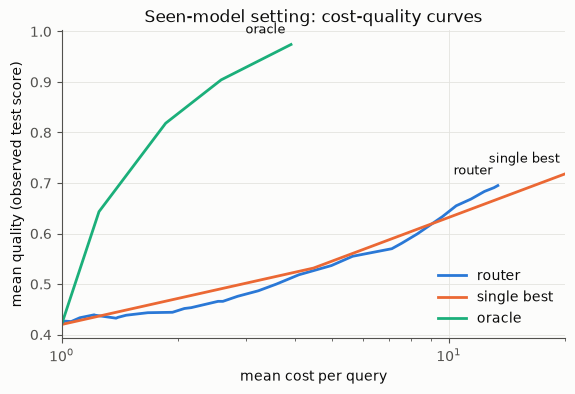

In [5]:
res = evaluate(data, fit, k=10)

fig, ax = plt.subplots()
for name, c in res["curves"].items():
    ax.plot(c[:, 0], c[:, 1], color=SERIES[name], label=name.replace("_", " "))
    ax.annotate(name.replace("_", " "), c[0], xytext=(-4, 8), textcoords="offset points",
                color=INK, fontsize=9, ha="right")  # label the λ = 0 end of each curve
ax.set(xlabel="mean cost per query", ylabel="mean quality (observed test score)",
       xscale="log", xlim=(data.cost.min(), data.cost.max()), title="Seen-model setting: cost-quality curves")
ax.legend(frameon=False, loc="lower right")
plt.show()

Each curve goes from the cheapest model (λ large, bottom left, where all three meet) to the best-quality routing (λ = 0, labeled end).
The x-axis is logarithmic and spans the full cost range of the pool, `[cheapest, most expensive]`, which is the range `A` is integrated over. Past its last point a curve is flat, since it cannot get better quality for more budget.

The oracle sees the realized, noisy outcomes, so it is not attainable. The single best is the bar to beat.

## 5. The area, the gain and `A`

`area` takes the curve, makes it monotone (best quality within a budget), interpolates linearly in cost between operating points, and integrates over `log(cost)` from the cheapest to the most expensive model, so every price decade weighs the same.

- **Main metric, the gain:** `area_router / area_single_best − 1`, a direct comparison with the single best.
- **Secondary, `A`:** `area_router / area_oracle`, reported in parentheses.

In [6]:
cost_range = (data.cost.min(), data.cost.max())
a = {name: area(c, *cost_range) for name, c in res["curves"].items()}
print({name: round(float(v), 3) for name, v in a.items()})
print(f"gain over single best: {a['router'] / a['single_best'] - 1:+.1%}   (evaluate says {res['gain']:+.1%})")
print(f"(A = {res['A']:.3f} vs {res['A_single_best']:.3f} for the single best)")

{'router': 1.629, 'single_best': 1.595, 'oracle': 2.667}
gain over single best: +2.1%   (evaluate says +2.1%)
(A = 0.611 vs 0.598 for the single best)


## 6. Unseen-model setting

Hold one model out. `evaluate(data, fit, new_model=..., n_probes=...)`:
- calls `fit(pool)` with the pool **without** the held-out model (a learned embedding retrains here),
- estimates the other models' quality from all training queries as before,
- estimates the new model's quality from **only its `n_probes` probe queries** (its own neighbor search),
- routes over all models, including the new one.

Below, the gain over the single best for the held-out `model2` as the probe budget grows (mean over 5 random probe sets, shaded band = min to max).
The single best is estimated from the same `n` probes, so both sides are equally informed.

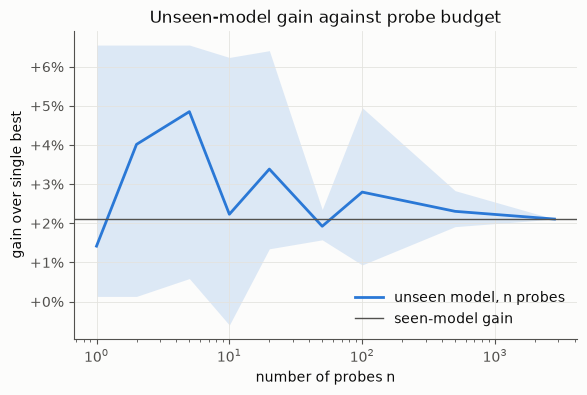

n = all training queries gives the seen result: True


In [7]:
n_grid = [1, 2, 5, 10, 20, 50, 100, 500, len(data.train)]
runs = np.array([[evaluate(data, fit, new_model="model2", n_probes=n, seed=s)["gain"] for s in range(5)]
                 for n in n_grid])

fig, ax = plt.subplots()
ax.plot(n_grid, runs.mean(1), color=SERIES["router"], label="unseen model, n probes")
ax.fill_between(n_grid, runs.min(1), runs.max(1), color=SERIES["router"], alpha=0.15, linewidth=0)
ax.axhline(res["gain"], color=MUTED, linewidth=1, label="seen-model gain")
ax.set(xscale="log", xlabel="number of probes n", ylabel="gain over single best",
       title="Unseen-model gain against probe budget")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:+.0%}"))
ax.legend(frameon=False, loc="lower right")
plt.show()

print("n = all training queries gives the seen result:",
      np.isclose(runs[-1].mean(), res["gain"]))

With few probes the gain is **larger** than the seen-model gain. This is not the router being better: with few probes the single best, whose model qualities are estimated from the same few probes, often picks the wrong model, so it is a weaker baseline.
Which baseline to use in the unseen setting (and how to define probes-to-target on the gain) is still to be decided.

## Status

**Done (phase 1):** kNN estimator, routing, λ sweep, single-best baseline, oracle, area `A` and the gain, `evaluate` for the seen and unseen settings, and tests on synthetic data (`test_router.py`).

**Provisional:**
- Integration range, oracle definition and λ grid for `A` (the cost axis is decided: log).
- The single-best baseline in the unseen setting, and probes-to-target (to be redefined on the gain).
- Probes are drawn by a seeded random sampler inside `evaluate`, standing in for Arman's probe sets.
- The mean cost per model and the `Data` format depend on Arman's schema.

**Next:** a bootstrap confidence interval for the gain, tuning `k` on a validation split, sensitivity to λ, the results CSV, the shared `plots.py`, and probes-to-target once it is defined.